In [1]:
import os
os.environ['KERAS_BACKEND'] = 'torch'    # has to be set before keras is imported

import numpy as np
import keras
# Set the seed for reproducibility (python, numpy and the backend)
keras.utils.set_random_seed(1234)

from keras.layers import Activation, BatchNormalization, Conv2D, Conv2DTranspose, MaxPooling2D, Dropout
from model_base import ModelBase, plot_history, visualize_result
import cv2

In [2]:
class SimpleModel(ModelBase):
    def __init__(self):
        super().__init__('Ct32_2xC32')

    def create(self, inputs):
        net = Conv2DTranspose(32, 3, strides=2, padding='same')(inputs)
        net = BatchNormalization()(net)
        net = Activation("relu")(net)
        net = Conv2D(32, kernel_size=(3, 3), padding='same')(net)
        net = BatchNormalization()(net)
        net = Activation("relu")(net)
        net = Conv2D(32, kernel_size=(3, 3), padding='same')(net)
        net = BatchNormalization()(net)
        net = Activation("relu")(net)
        return Conv2D(3, 1, activation="sigmoid")(net)

class ConvCTConvModel(ModelBase):
    def __init__(self):
        super().__init__('2xC32_Ct32_2xC64')

    def create(self, inputs):
        net = Conv2D(32, kernel_size=(3, 3), padding='same')(inputs)
        net = BatchNormalization()(net)
        net = Activation("relu")(net)
        net = Conv2D(32, kernel_size=(3, 3), padding='same')(net)
        net = BatchNormalization()(net)
        net = Activation("relu")(net)
        net = Conv2DTranspose(32, 3, strides=2, padding='same')(net)
        net = BatchNormalization()(net)
        net = Activation("relu")(net)
        net = Conv2D(64, kernel_size=(3, 3), padding='same')(net)
        net = BatchNormalization()(net)
        net = Activation("relu")(net)
        net = Conv2D(64, kernel_size=(3, 3), padding='same')(net)
        net = BatchNormalization()(net)
        net = Activation("relu")(net)
        return Conv2D(3, 1, activation="sigmoid")(net)

class BottleneckModel(ModelBase):
    def __init__(self):
        super().__init__('2xC32_P2_Ct32_2xC32_Ct64_2xC64', batch_size=16)

    def create(self, inputs):
        net = Conv2D(32, kernel_size=(5, 5), padding='same')(inputs)
        net = BatchNormalization()(net)
        net = Activation("relu")(net)
        net = Conv2D(32, kernel_size=(5, 5), padding='same')(net)
        net = BatchNormalization()(net)
        net = Activation("relu")(net)
        net = MaxPooling2D(pool_size=(2, 2))(net)
        
        net = Conv2D(64, kernel_size=(5, 5), padding='same')(net)
        net = BatchNormalization()(net)
        net = Activation("relu")(net)
        
        net = Conv2DTranspose(32, 5, strides=2, padding='same')(net)
        net = BatchNormalization()(net)
        net = Activation("relu")(net)
        net = Conv2D(32, kernel_size=(5, 5), padding='same')(net)
        net = BatchNormalization()(net)
        net = Activation("relu")(net)
        net = Conv2D(32, kernel_size=(5, 5), padding='same')(net)
        net = BatchNormalization()(net)
        net = Activation("relu")(net)

        net = Conv2DTranspose(64, 5, strides=2, padding='same')(net)
        net = BatchNormalization()(net)
        net = Activation("relu")(net)
        net = Conv2D(64, kernel_size=(5, 5), padding='same')(net)
        net = BatchNormalization()(net)
        net = Activation("relu")(net)
        net = Conv2D(64, kernel_size=(5, 5), padding='same')(net)
        net = BatchNormalization()(net)
        net = Activation("relu")(net)
        return Conv2D(3, 1, activation="sigmoid")(net)

model = BottleneckModel()
model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 64, 64, 32)     │         2,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 64, 64, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 64, 32)     │        25,632 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 64, 64, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 32, 32, 64)     │        51,264 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 32, 32, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose                │ (None, 64, 64, 32)     │        51,232 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 64, 64, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 64, 64, 32)     │        25,632 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 64, 64, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_4 (Activation)       │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 64, 64, 32)     │        25,632 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 64, 64, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_5 (Activation)       │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_1              │ (None, 128, 128, 64)   │        51,264 │
│ (Conv2DTranspose)               │                        │             

 Total params: 439,875 (1.68 MB)

 Trainable params: 439,043 (1.67 MB)

 Non-trainable params: 832 (3.25 KB)

In [3]:
history = model.fit()

Epoch 1/50
129/129 - 19s - 146ms/step - accuracy: 0.1929 - loss: 0.5260 - val_accuracy: 0.4991 - val_loss: 0.5676
Epoch 2/50
129/129 - 19s - 145ms/step - accuracy: 0.3638 - loss: 0.2986 - val_accuracy: 0.4621 - val_loss: 0.4445
Epoch 3/50
129/129 - 18s - 140ms/step - accuracy: 0.3969 - loss: 0.2683 - val_accuracy: 0.4107 - val_loss: 0.3176
Epoch 4/50
129/129 - 22s - 167ms/step - accuracy: 0.5753 - loss: 0.2484 - val_accuracy: 0.5307 - val_loss: 0.2486
Epoch 5/50
129/129 - 25s - 191ms/step - accuracy: 0.6385 - loss: 0.2379 - val_accuracy: 0.5895 - val_loss: 0.2593
Epoch 6/50
129/129 - 26s - 202ms/step - accuracy: 0.6551 - loss: 0.2300 - val_accuracy: 0.6531 - val_loss: 0.2379
Epoch 7/50
129/129 - 25s - 192ms/step - accuracy: 0.6528 - loss: 0.2297 - val_accuracy: 0.5443 - val_loss: 0.2792
Epoch 8/50
129/129 - 25s - 194ms/step - accuracy: 0.6586 - loss: 0.2246 - val_accuracy: 0.4624 - val_loss: 0.2527
Epoch 9/50
129/129 - 25s - 193ms/step - accuracy: 0.6600 - loss: 0.2257 - val_accuracy: 

Train Acc      0.7000866532325745
Validation Acc 0.5745149254798889


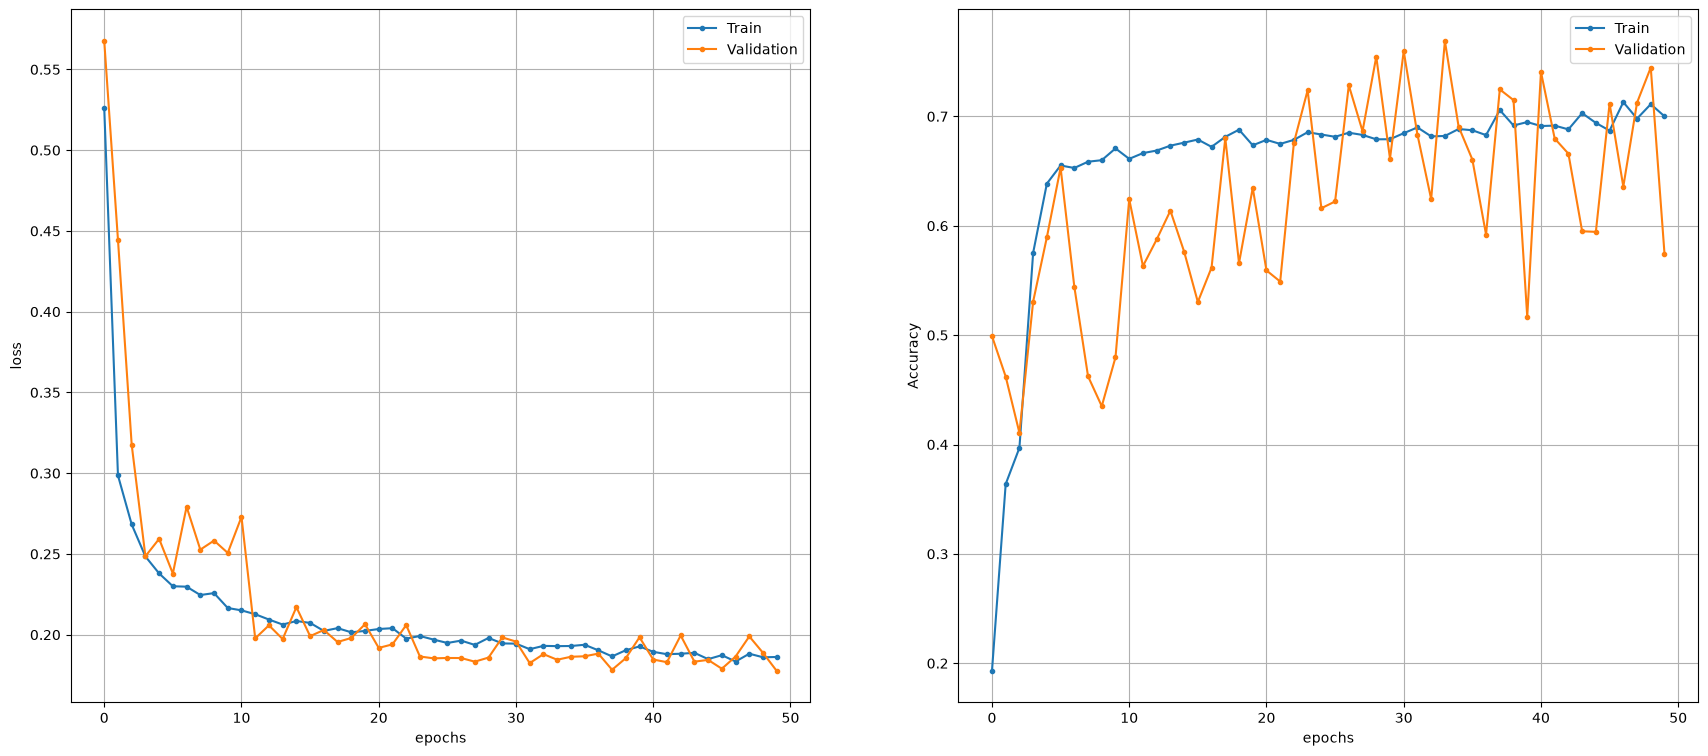

In [4]:
plot_history(history)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step


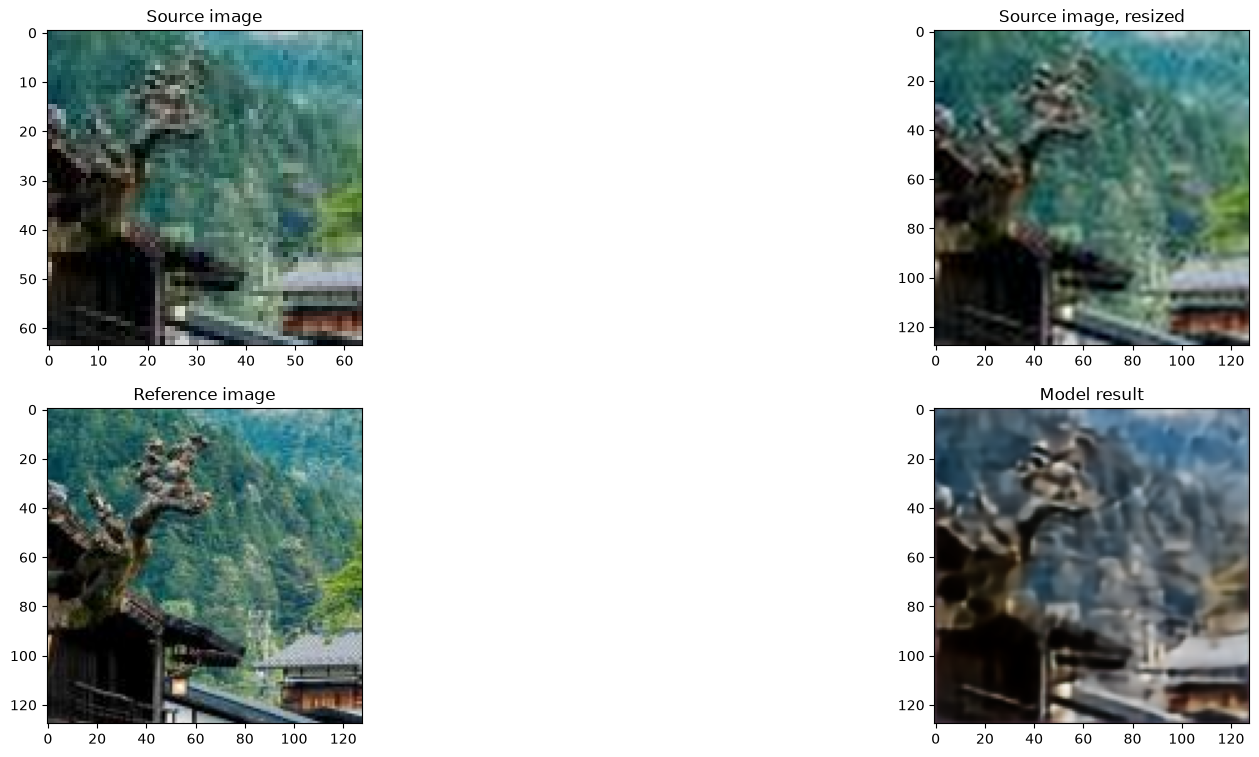

In [5]:
from dataset_location import DatasetLocation
x = cv2.imread(os.path.join(DatasetLocation.ROOT, 'test', '1.jpg')).astype(np.float32) / 255
y = cv2.imread(os.path.join(DatasetLocation.ROOT, 'test', '2.jpg')).astype(np.float32) / 255
visualize_result(model, x, y)